# 14 — Dual-pol covariance matrix C2: reconstruction and validation

**Goal:** build the 2x2 covariance matrix

C2 = [[⟨|S_HH|²⟩, ⟨S_HH S_HV*⟩], [⟨S_HV S_HH*⟩, ⟨|S_HV|²⟩]]

from the complex GSLC images, by spatial averaging (multilooking), and check it is physically valid.
The off-diagonal term stays **complex** (its phase is information; replacing it by its magnitude
changes the decompositions).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # training/notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "14"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
import h5py
from nisar_s1 import polarimetry as pol
session = P.load_session(kit["session_file"], required=("gslc_subsets", "aoi_bounds"))

In [2]:
src = Path(session["gslc_subsets"][0])          # before the cut (18 July 2026)
with h5py.File(src) as h5:
    prof = P.product_profile(h5)
    g = prof.grids["frequencyA"]
    win = P.window_from_bounds(g, g.bounds)
    hh = P.read_layer(h5, g, "HH", win)
    hv = P.read_layer(h5, g, "HV", win)
print(prof.granule[:70]); print("SLC window", hh.shape, hh.dtype, f"pixel {g.dx:.2f} x {-g.dy:.2f} m")

NISAR_L2_PR_GSLC_025_144_A_026_2005_DHDH_M_20260718T041939_20260718T04
SLC window (1148, 622) complex64 pixel 10.00 x 5.00 m


## Number of looks
Entropy and α are **biased** when estimated from few looks (entropy is underestimated). We average
to ~40 m, which gives a comparable number of looks for NISAR and Sentinel-1 (notebook 18).

In [3]:
target = kit["gslc"]["target_pixel_m"]
looks = (max(1, round(target / abs(g.dy))), max(1, round(target / g.dx)))
c2 = pol.c2_from_slc(hh, hv, looks=looks)
print(f"looks (rows x cols) = {looks} -> {looks[0] * looks[1]} looks, output pixel "
      f"{looks[1] * g.dx:.0f} x {looks[0] * abs(g.dy):.0f} m, shape {c2.c11.shape}")
chk = pol.validate_c2(c2); pd.Series(chk).round(5)

looks (rows x cols) = (8, 4) -> 32 looks, output pixel 40 x 40 m, shape (143, 155)


n_valid                22165.00000
frac_invalid               0.00000
frac_negative_power        0.00000
frac_rho_above_1           0.00000
frac_negative_det          0.00000
max_trace_error            0.00000
median_abs_rho             0.21298
dtype: float64

## Validation against the GCOV of the same date
GCOV `HHHH` is γ⁰ (terrain-normalized) while |GSLC|² is not terrain-normalized: values differ by a
slope-dependent factor and by speckle, so the correlation is high but not perfect (≈ 0.8 here).
The decisive test is **where** the correlation peaks: shifting one image by a single 40 m pixel
must lower it. A peak away from zero shift would reveal a geolocation error.

GCOV date 20260718: Pearson r (dB) = 0.789, median offset GSLC-GCOV = -1.01 dB, n = 9025
correlation by shift (rows, cols): {(-1, -1): np.float64(0.45), (-1, 0): np.float64(0.51), (-1, 1): np.float64(0.42), (0, -1): np.float64(0.58), (0, 0): np.float64(0.79), (0, 1): np.float64(0.49), (1, -1): np.float64(0.5), (1, 0): np.float64(0.52), (1, 1): np.float64(0.39)}
best shift: (0, 0)


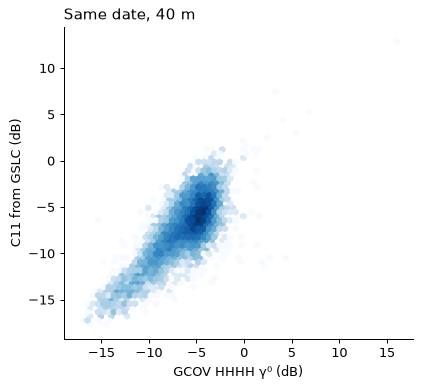

In [4]:
from nisar_s1.grid import read_geotiff, to_grid
from nisar_s1.optical import Raster
from nisar_s1.config import load_params
import re
day = re.search(r"_(\d{8})T", prof.granule).group(1)
gc = sorted((Path(load_params()["chemins"]["processed"]) / "nisar" / "A144F26" / "GCOV").glob(f"*_{day}T*__HHHH.tif"))
from affine import Affine
ml_tr = win.transform @ Affine.scale(looks[1], looks[0])
c11_r = Raster(c2.c11, ml_tr, win.crs)
if gc:
    gref = to_grid(read_geotiff(gc[0]), c11_r)          # GCOV γ0 HH averaged onto the C2 grid
    a, b = pol.to_db(c11_r.data), pol.to_db(gref.data)
    ok = np.isfinite(a) & np.isfinite(b)
    r = np.corrcoef(a[ok], b[ok])[0, 1]
    print(f"GCOV date {day}: Pearson r (dB) = {r:.3f}, median offset GSLC-GCOV = {np.median(a[ok]-b[ok]):+.2f} dB, n = {ok.sum()}")
    # geolocation test: the correlation must peak at zero shift (a 1-pixel error would move the peak)
    shifts = {}
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            aa = np.roll(np.roll(a, dy, 0), dx, 1); o = ok & np.isfinite(aa)
            shifts[(dy, dx)] = np.corrcoef(aa[o], b[o])[0, 1]
    best = max(shifts, key=shifts.get)
    print("correlation by shift (rows, cols):", {k: round(v, 2) for k, v in shifts.items()})
    print("best shift:", best)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.hexbin(b[ok], a[ok], gridsize=60, bins="log", cmap="Blues")
    ax.set_xlabel("GCOV HHHH γ⁰ (dB)"); ax.set_ylabel("C11 from GSLC (dB)"); ax.set_title("Same date, 40 m", loc="left")
    plt.show()
else:
    r, best = np.nan, (0, 0); print("no GCOV GeoTIFF of the same date found: validation skipped")

In [5]:
np.savez_compressed(OUT / "c2_pre.npz", c11=c2.c11, c22=c2.c22, c12=c2.c12, transform=list(ml_tr)[:6], crs=win.crs)
P.save_session(kit["session_file"], c2_looks=list(looks))

{'granule': 'NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001',
 'gcov_local': '/media/dell/Transcend1/nisar_data/kit/gcov/NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5',
 'gcov_url': 'https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_V1/NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001/NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5',
 'product_type': 'GCOV',
 'epsg_hint': 32632,
 'frequency': 'frequencyA',
 'epsg': 32632,
 'polarimetric_mode': 'dual-pol linear (HH/HV)',
 'terms': ['HHHH', 'HVHV'],
 'aoi_name': 'vosges_c11',
 'aoi_bbox_wgs84': [6.716, 47.885, 6.797, 47.935],
 'aoi_bounds': [329250.0627272764,
  5305867.839017732,
  335463.8838031237,
  5311600.571279069],
 'aoi_window': {'rows': [11295, 11583],
  'cols': [4726, 5038],
  'transform': [20.0, 0.0, 329240.0, 0.0, -20.0, 5311620.0],


In [6]:
checks = {
    "no |rho| > 1": chk['frac_rho_above_1'] == 0,
    "no negative determinant": chk['frac_negative_det'] == 0,
    "trace = sum of eigenvalues": chk['max_trace_error'] < 1e-3,
    "consistent with GCOV (r > 0.6)": np.isnan(r) or r > 0.6,
    "correlation peaks at zero shift": best == (0, 0),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 14 STATUS: PASS")

  [x] no |rho| > 1
  [x] no negative determinant
  [x] trace = sum of eigenvalues
  [x] consistent with GCOV (r > 0.6)
  [x] correlation peaks at zero shift
Module 14 STATUS: PASS
